# Which images does Ramen confuse, and with what? Per-image records on CIFAR-100-C

**Question.** When the zero-shot model or Ramen gets an image wrong, which class does it pick instead? What do
those images look like? And how does one adaptation step change the image's embedding and prediction?

**What this notebook is.** This is a tool for looking at errors, not a test of a new method. Nothing here
changes Ramen. Every image is run through `RamenRecorder` (`src/methods/RamenRecorder.py`). This is Ramen with
one addition: it records four things for each image:

| record | what it is |
|---|---|
| `zs_probs` | zero-shot softmax over the 100 classes, from the pass before adaptation (this pass also decides which memory queue the image is filed in) |
| `probs` | Ramen's softmax, after its one signSGD step on the norm parameters |
| `emb_before` | L2-normalised CLIP image embedding with the pretrained norm parameters (= the zero-shot embedding) |
| `emb_after` | the same embedding with the adapted norm parameters (the one Ramen classifies) |

The `zero_shot → ramen` **outcome** of each image is one of: right → right, *fixed*, *broken*,
wrong → same wrong, wrong → other wrong. The **embedding shift** is 1 − cos(before, after).

The class confusion of each source is a 100 × 100 count matrix: rows are the true class, columns the predicted
class (`confusion.py`). For one class *c* over the N images:
- TP: true *c*, predicted *c*
- FN: true *c*, predicted something else
- FP: true something else, predicted *c*
- TN: everything else

**Data and model.** CIFAR-100-C, severity 5, is a **full run** on **15 corruptions × 10,000 images =
150,000**, in **100 classes**. Every corruption applies to the same 10,000 test images. Model: CLIP ViT-B/16
(images upsampled from 32 × 32). Ramen config: `cfg/CIFAR100C/Ramen.yaml` (capacity 750 per class, top-k 5, β 5,
lr 0.01, signSGD). One mixed, shuffled stream over all corruptions, batch size 100. **Seed 0** sets the stream
order. Known baseline, seed 0: NoAdapt 37.10 → Ramen 46.10. Seeds 0–4 give a noise floor of 0.21.

**How the results were produced.**
```
cd new_experiments/2026-10-28_confusion_records
CUDA_VISIBLE_DEVICES=0 nice -n 10 python run_records.py CIFAR100C 0
```
The run is cached under `new_experiments/results/CIFAR100C_clip_vitbase16_mixed_nall_bs100_s0_rec_Ramen*`.
Code: `experiment.py` (RecordExperiment), `records.py` (ImageRecords), `confusion.py` (ConfusionMatrix,
ConfusionShift), `gallery.py` (ConfusionGallery), `plots.py`.

**Sanity check (what counts as valid).** The recorder must not change Ramen. Its predictions must equal those of
plain Ramen on the same stream for 100.00% of images (cell 2). The recorded zero-shot prediction is compared with
the separate NoAdapt run for information only. The two use different model wrappers, so fp16 near-ties can flip a
handful of images.

In [1]:
import sys
sys.path.insert(0, '.')
import warnings; warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from experiment import RecordExperiment, count_pct
import plots

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

# ---- settings: change these to look at something else -------------------------------------------------
DATASET, SEED = 'CIFAR100C', 0
N_PER_DOMAIN = None                      # None = the whole dataset; an int = that many images per domain
FOCUS_CLASS = 'keyboard'                        # one class to inspect in detail
FOCUS_PAIR = ('maple_tree', 'oak_tree')                          # one (true, predicted) confusion to inspect
OLD_SINK = 'worm'                              # a class zero-shot over-predicts
NEW_SINK = 'crab'                              # a class Ramen over-predicts more than zero-shot does

In [2]:
exp = RecordExperiment(DATASET, seed=SEED, n_per_domain=N_PER_DOMAIN).run()   # cached -> no GPU needed
assert exp.sanity_check(), 'the recorder changed Ramen'
records = exp.records
zs, ra = exp.confusion('zero_shot'), exp.confusion('ramen')
shift = exp.shift()
print(f'{len(records):,} images recorded; vectors: ' +
      ', '.join(f'{k} {tuple(v.shape)} {v.dtype}' for k, v in records.arrays.items()))

Ramen: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/CIFAR100C_clip_vitbase16_mixed_nall_bs100_s0_Ramen.pkl
recorded Ramen prediction == Ramen: 150,000 of 150,000 (100.0%)
NoAdapt: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/CIFAR100C_clip_vitbase16_mixed_nall_bs100_s0_NoAdapt.pkl
recorded zero-shot prediction == NoAdapt: 149,290 of 150,000 (99.5%)
150,000 images recorded; vectors: zs_pred (150000,) int32, zs_probs (150000, 100) float16, probs (150000, 100) float16, emb_before (150000, 512) float16, emb_after (150000, 512) float16


## The data

Images and classes present per domain. These are the denominators for everything below. Each class has 100 images per corruption, so 1,500 in total: per-class counts are large enough to read.

In [3]:
display(exp.data_table())
support = records.table['label'].value_counts()
print(f'images per class: median {support.median():.0f}, min {support.min()}, max {support.max()}')

,images,classes present
domain,,
gaussian_noise,10000,100
shot_noise,10000,100
impulse_noise,10000,100
defocus_blur,10000,100
glass_blur,10000,100
motion_blur,10000,100
zoom_blur,10000,100
snow,10000,100
frost,10000,100


images per class: median 1500, min 1500, max 1500


## Headline: zero-shot vs Ramen

Accuracy per domain, with counts. Below that, each image's outcome from zero-shot to Ramen. The net gain is
*fixed − broken*.

,images,zero-shot correct,Ramen correct,zero-shot %,Ramen %,Δ (pts)
domain,,,,,,
gaussian_noise,10000,2285,3037,22.85,30.37,7.52
shot_noise,10000,2440,3198,24.40,31.98,7.58
impulse_noise,10000,2957,4294,29.57,42.94,13.37
defocus_blur,10000,4358,5260,43.58,52.60,9.02
glass_blur,10000,2015,2895,20.15,28.95,8.80
motion_blur,10000,4359,5238,43.59,52.38,8.79
zoom_blur,10000,4862,5574,48.62,55.74,7.12
snow,10000,4893,5530,48.93,55.30,6.37
frost,10000,5045,5440,50.45,54.40,3.95


outcome,right -> right,fixed,broken,wrong -> same wrong,wrong -> other wrong
domain,,,,,
gaussian_noise,1852,1185,433,2208,4322
shot_noise,2010,1188,430,2228,4144
impulse_noise,2645,1649,312,2388,3006
defocus_blur,3871,1389,487,2006,2247
glass_blur,1627,1268,388,2175,4542
motion_blur,3875,1363,484,1940,2338
zoom_blur,4376,1198,486,2006,1934
snow,4375,1155,518,1883,2069
frost,4466,974,579,2003,1978


fixed                  20,301 of 150,000 (13.5%)
broken                 6,792 of 150,000 (4.5%)
wrong -> same wrong    30,300 of 150,000 (20.2%)
wrong -> other wrong   43,764 of 150,000 (29.2%)


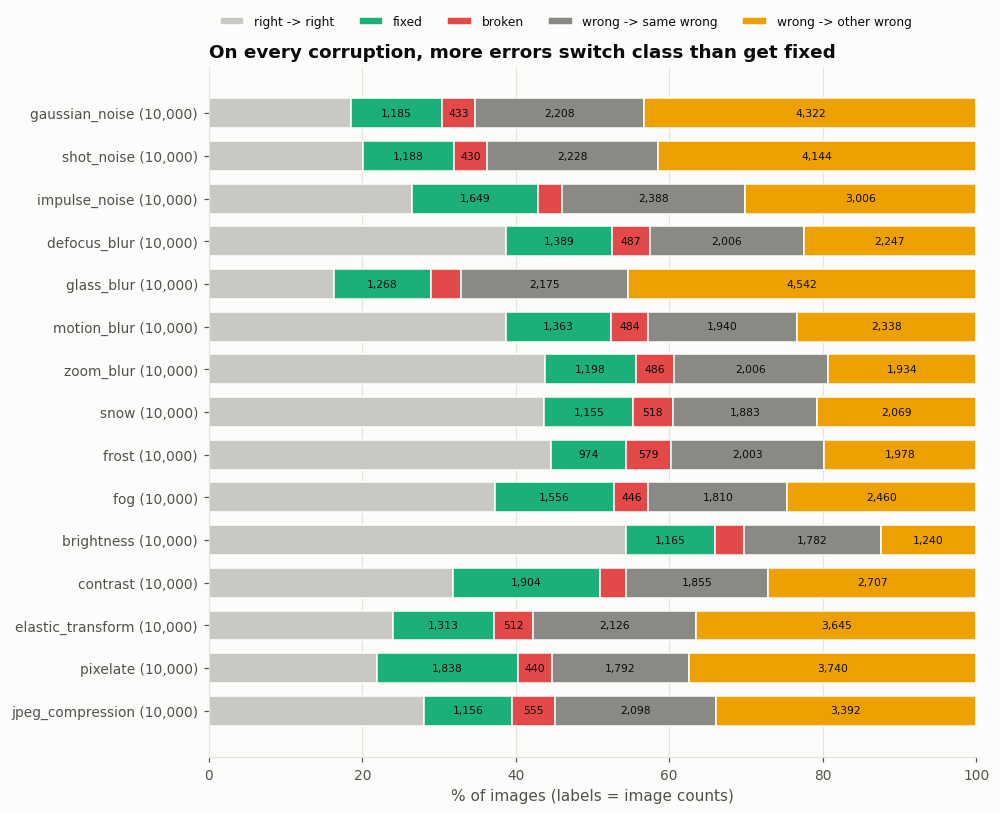

In [4]:
display(exp.accuracy_table())
ot = exp.outcome_table(by='domain')
display(ot)
n = len(records)
for o in ['fixed', 'broken', 'wrong -> same wrong', 'wrong -> other wrong']:
    print(f'{o:22s} {count_pct(int(ot.loc["all", o]), n)}')
plots.plot_outcomes(ot.drop('all'), title='On every corruption, more errors switch class than get fixed')
plt.show()

## 1. Per-class confusion: TP, FP, FN, TN

`ConfusionMatrix.per_class()` lists every class. The interesting classes are **sinks**: classes predicted far more
often than they occur, which shows up as a large FP. The table below compares zero-shot and Ramen on the classes
whose FP changes most.

In [5]:
pc = shift.per_class()
pc['predicted zero_shot'] = zs.counts.sum(0); pc['predicted ramen'] = ra.counts.sum(0)
cols = ['support', 'predicted zero_shot', 'predicted ramen', 'TP zero_shot', 'TP ramen', 'FP zero_shot', 'FP ramen', 'ΔFP',
        'FN zero_shot', 'FN ramen', 'ΔFN']
print('Classes whose false positives Ramen REMOVES most (zero-shot sinks):')
display(pc.sort_values('ΔFP')[cols].head(8))
print('Classes whose false positives Ramen ADDS most (new sinks):')
display(pc.sort_values('ΔFP', ascending=False)[cols].head(8))

Classes whose false positives Ramen REMOVES most (zero-shot sinks):


,support,predicted zero_shot,predicted ramen,TP zero_shot,TP ramen,FP zero_shot,FP ramen,ΔFP,FN zero_shot,FN ramen,ΔFN
class,,,,,,,,,,,
worm,1500,5283,1837,1019,850,4264,987,-3277,481,650,169
mouse,1500,4761,1822,225,237,4536,1585,-2951,1275,1263,-12
girl,1500,4371,1610,800,754,3571,856,-2715,700,746,46
keyboard,1500,3500,881,933,625,2567,256,-2311,567,875,308
willow_tree,1500,3725,1938,672,562,3053,1376,-1677,828,938,110
cloud,1500,3079,1582,814,871,2265,711,-1554,686,629,-57
woman,1500,3085,1731,861,775,2224,956,-1268,639,725,86
rocket,1500,3152,2190,953,1059,2199,1131,-1068,547,441,-106


Classes whose false positives Ramen ADDS most (new sinks):


,support,predicted zero_shot,predicted ramen,TP zero_shot,TP ramen,FP zero_shot,FP ramen,ΔFP,FN zero_shot,FN ramen,ΔFN
class,,,,,,,,,,,
crab,1500,796,2389,400,761,396,1628,1232,1100,739,-361
tractor,1500,1205,2557,662,1033,543,1524,981,838,467,-371
lion,1500,994,2251,535,896,459,1355,896,965,604,-361
leopard,1500,295,1109,90,268,205,841,636,1410,1232,-178
kangaroo,1500,1334,2184,407,646,927,1538,611,1093,854,-239
lawn_mower,1500,1416,2222,635,849,781,1373,592,865,651,-214
beaver,1500,1713,2492,233,465,1480,2027,547,1267,1035,-232
possum,1500,1817,2530,438,645,1379,1885,506,1062,855,-207


In [6]:
print('Ramen, per class, sorted by FP (TN is large for every class: N minus the rest):')
display(ra.per_class().sort_values('FP', ascending=False).head(10))

Ramen, per class, sorted by FP (TN is large for every class: N minus the rest):


,support,predicted,TP,FP,FN,TN,precision %,recall %,F1 %
class,,,,,,,,,
oak_tree,1500,3068,882,2186,618,146314,28.75,58.80,38.62
fox,1500,3143,979,2164,521,146336,31.15,65.27,42.17
beaver,1500,2492,465,2027,1035,146473,18.66,31.00,23.30
possum,1500,2530,645,1885,855,146615,25.49,43.00,32.01
hamster,1500,2715,934,1781,566,146719,34.40,62.27,44.32
pine_tree,1500,2448,759,1689,741,146811,31.00,50.60,38.45
skunk,1500,2494,812,1682,688,146818,32.56,54.13,40.66
crab,1500,2389,761,1628,739,146872,31.85,50.73,39.14
flatfish,1500,1884,274,1610,1226,146890,14.54,18.27,16.19


### Sink fate and sink origin

**Sink fate.** Take the images zero-shot wrongly sends to `OLD_SINK`. Does Ramen fix them, leave them there, or
move them to another wrong class?

**Sink origin.** Take Ramen's false positives of `NEW_SINK`. What did zero-shot predict for them?

In [7]:
fate, moved = exp.sink_fate(OLD_SINK)
display(fate.to_frame(f'{OLD_SINK}: images'))
display(moved.to_frame('images'))
n_fp, origin, domains = exp.sink_origin(NEW_SINK)
print(f'Ramen predicts {NEW_SINK} wrongly for {n_fp:,} images (zero-shot: {int(zs.fp[zs._idx(NEW_SINK)]):,})')
display(origin.to_frame('images')); display(domains.head(6).to_frame('images'))

,worm: images
zero-shot false positives,4264
fixed by Ramen,1095
still worm,675
moved to another wrong class,2494


,images
pred_class,
crab,139
snake,129
trout,128
cockroach,89
camel,87
shrew,82
skunk,80
beaver,74


Ramen predicts crab wrongly for 1,628 images (zero-shot: 396)


,images
zs_class,
crab,213
worm,143
flatfish,114
mushroom,89
shrew,61
cloud,49
pine_tree,40
poppy,40


,images
domain,
glass_blur,429
elastic_transform,196
contrast,150
frost,139
zoom_blur,137
motion_blur,99


## 2. One class in detail

Set `FOCUS_CLASS` in the settings cell. Three views:
1. its TP / FN / FP / TN under both sources;
2. where its images go (`predicted_as`, the row of the matrix);
3. which classes get called by its name (`mistaken_for`, the column).

Then the images themselves. Each caption shows the true class, then the zero-shot prediction with its probability
and the probability of the true class, then the same for Ramen, then the domain and the embedding shift.

zero-shot                  Ramen               
                                count      of      %   count      of      %
keyboard                                                                   
TP (true and predicted)           933    1500   62.2     625    1500  41.67
FN (true, predicted other)        567    1500   37.8     875    1500  58.33
FP (other, predicted as it)      2567    3500  73.34     256     881  29.06
TN (other, predicted other)    145933  148500  98.27  148244  148500  99.83

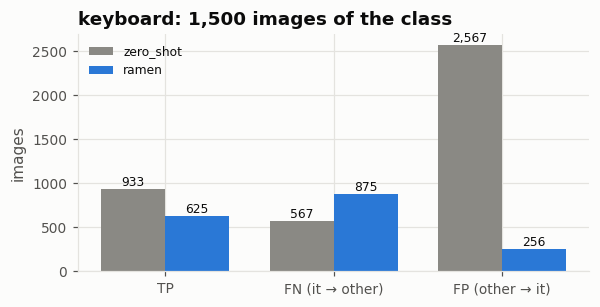

In [8]:
display(pd.concat({'zero-shot': zs.report(FOCUS_CLASS)[['count', 'of', '%']],
                   'Ramen': ra.report(FOCUS_CLASS)[['count', 'of', '%']]}, axis=1))
plots.plot_class_report(shift, FOCUS_CLASS); plt.show()

In [9]:
display(pd.concat({'zero-shot': zs.predicted_as(FOCUS_CLASS, 8).reset_index(),
                   'Ramen': ra.predicted_as(FOCUS_CLASS, 8).reset_index()}, axis=1))
display(pd.concat({'zero-shot': zs.mistaken_for(FOCUS_CLASS, 8).reset_index(),
                   'Ramen': ra.mistaken_for(FOCUS_CLASS, 8).reset_index()}, axis=1))

zero-shot                                                 Ramen                      
  images of keyboard predicted as count % of its images images of keyboard predicted as count % of its images
0                            worm    75            5.00                      television    69            4.60
1                           cloud    46            3.07                        mountain    52            3.47
2                             sea    35            2.33                            road    44            2.93
3                       telephone    34            2.27                             sea    44            2.93
4                           snake    28            1.87                            worm    35            2.33
5                        flatfish    24            1.60                           cloud    31            2.07
6                            road    23            1.53                      skyscraper    28            1.87
7                      skyscraper    21            1.40                          forest    25            1.67

zero-shot                                                                 Ramen                           
  true class of images predicted as keyboard count % of its predictions true class of images predicted as keyboard count % of its predictions
0                                 television   253                 7.23                                 television    52                 5.90
1                                      couch   193                 5.51                                  telephone    31                 3.52
2                                   wardrobe   192                 5.49                                      couch    26                 2.95
3                                        bed   153                 4.37                                        bed    20                 2.27
4                                  telephone   138                 3.94                                      clock    10                 1.14
5                                     bridge    64                 1.83                                 skyscraper     8                 0.91
6                                      table    63                 1.80                                   wardrobe     8                 0.91
7                                        bus    61                 1.74                                      chair     7                 0.79

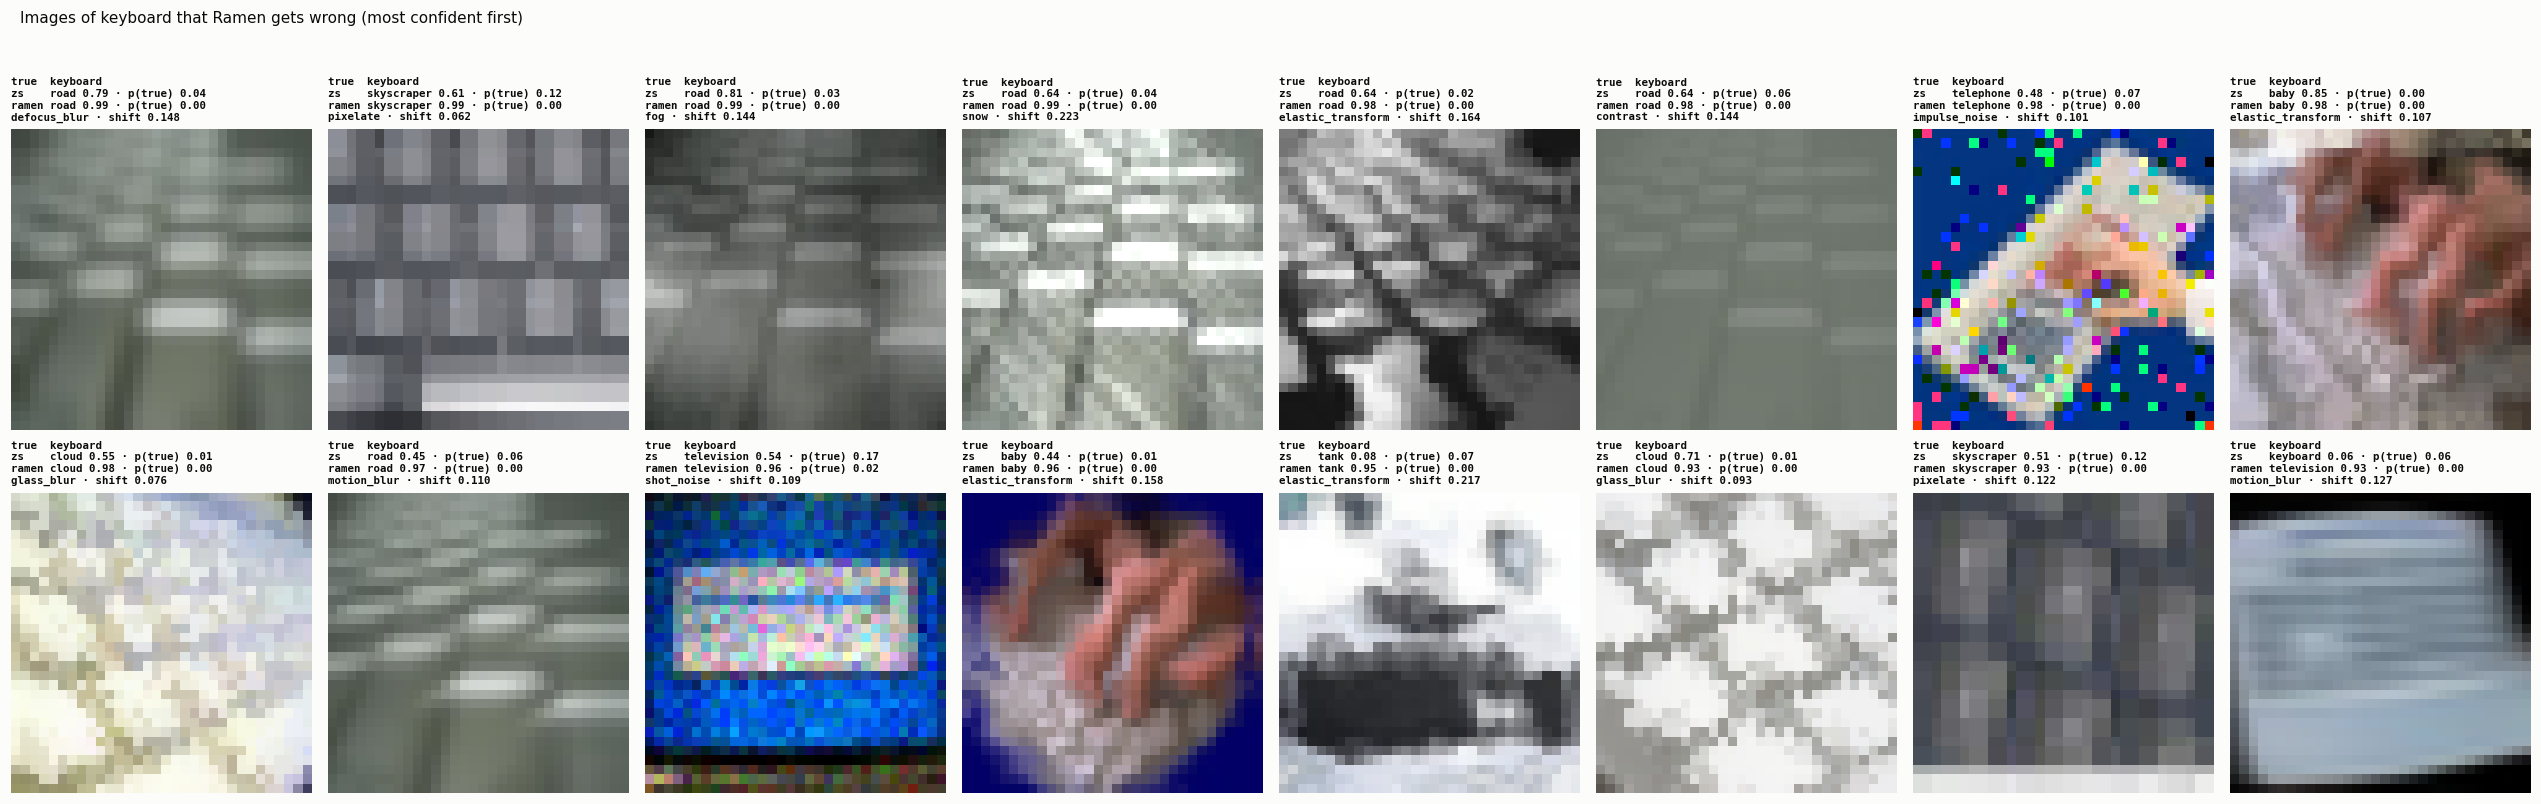

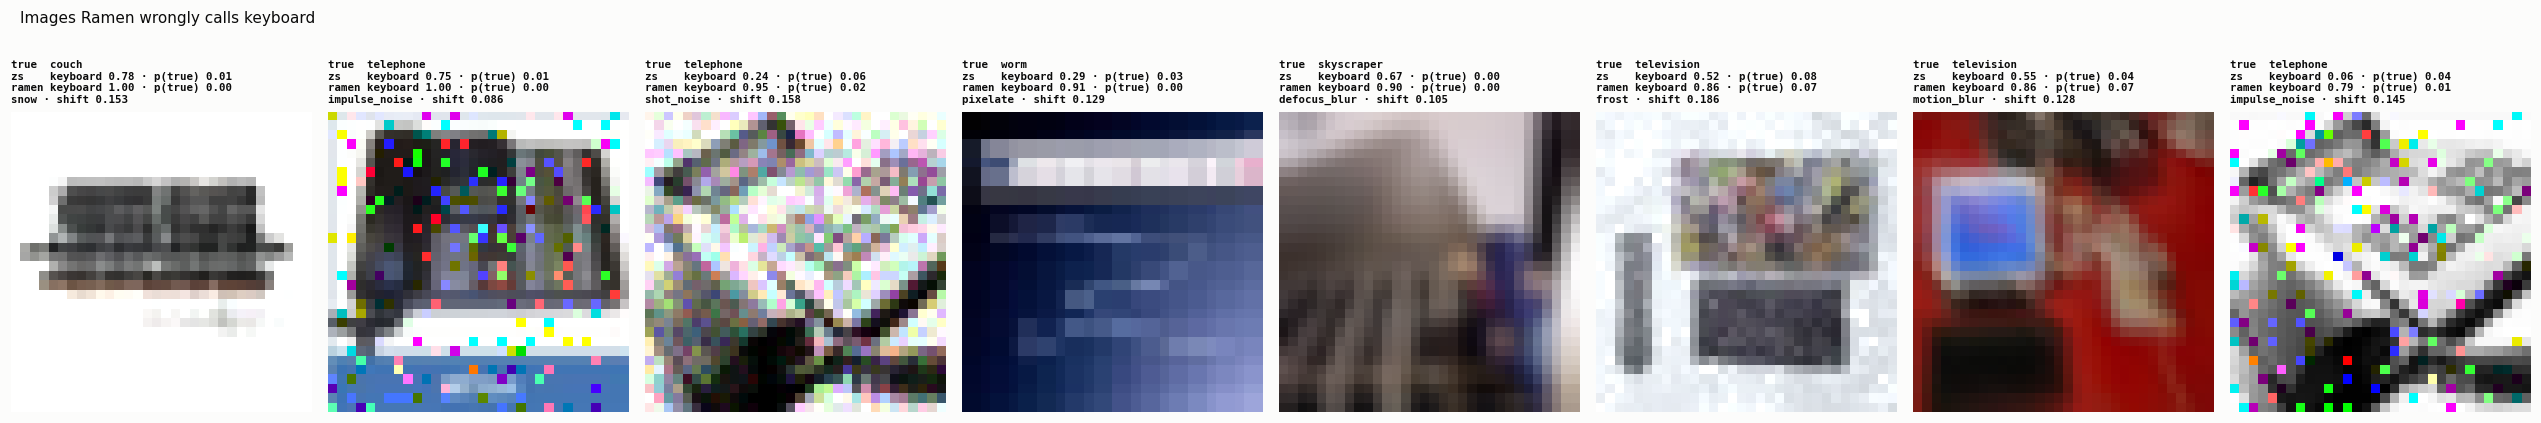

In [10]:
exp.gallery.show(true=FOCUS_CLASS, correct=False, n=16, title=f'Images of {FOCUS_CLASS} that Ramen gets wrong '
                 f'(most confident first)'); plt.show()
exp.gallery.show(pred=FOCUS_CLASS, correct=False, n=8, title=f'Images Ramen wrongly calls {FOCUS_CLASS}'); plt.show()

## 3. Confused pairs

These are the largest off-diagonal cells under each source, then the pairs that change most from zero-shot to Ramen.

In [11]:
display(pd.concat({'zero-shot': zs.top_pairs(12), 'Ramen': ra.top_pairs(12)}, axis=1))

zero-shot                                           Ramen                                 
           true    predicted count % of true class         true  predicted count % of true class
0    maple_tree     oak_tree   476           31.73   maple_tree   oak_tree   509           33.93
1         snake         worm   459           30.60        whale    dolphin   418           27.87
2     cockroach       beetle   388           25.87  willow_tree   oak_tree   329           21.93
3         whale      dolphin   344           22.93      dolphin      shark   294           19.60
4         woman         girl   337           22.47    pine_tree   oak_tree   293           19.53
5   caterpillar         worm   307           20.47    cockroach     beetle   292           19.47
6          girl        woman   307           20.47     oak_tree  pine_tree   291           19.40
7      oak_tree  willow_tree   299           19.93    streetcar        bus   285           19.00
8         trout     flatfish   287           19.13        woman       girl   284           18.93
9    maple_tree  willow_tree   286           19.07        table      chair   268           17.87
10    pine_tree     oak_tree   285           19.00         worm      snake   268           17.87
11          cup         lamp   279           18.60          can     bottle   264           17.60

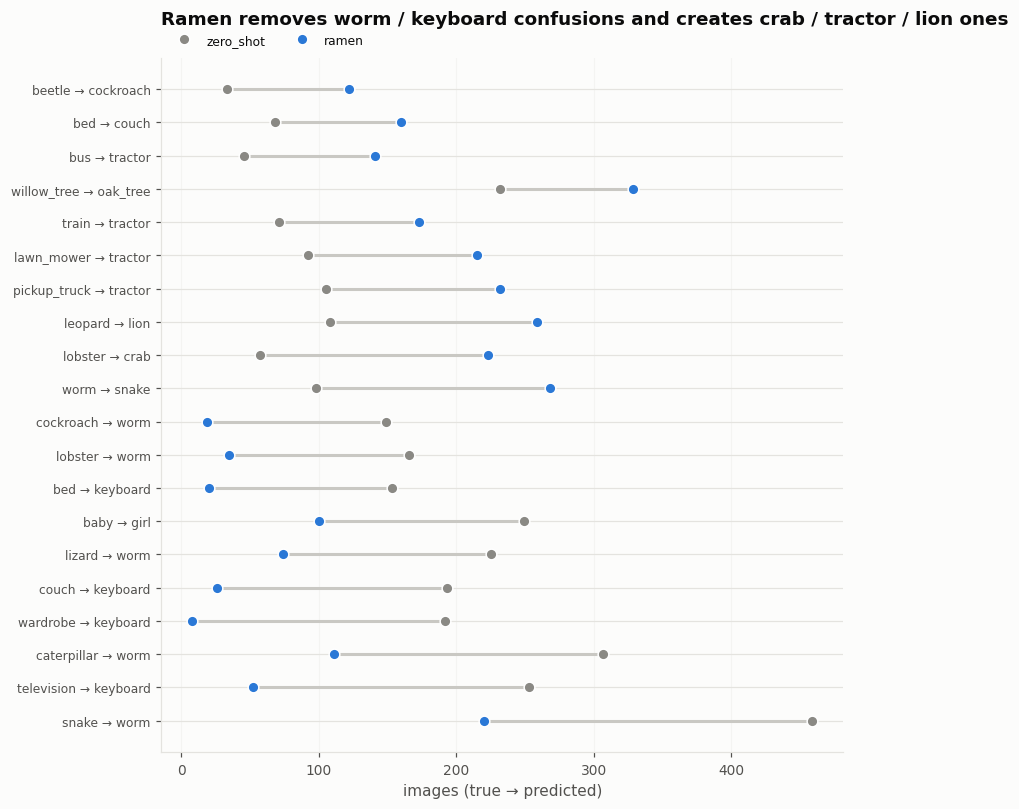

In [12]:
changes = pd.concat([shift.pair_changes(10, 'shrank'), shift.pair_changes(10, 'grew')]).drop_duplicates()
plots.plot_pair_changes(changes.iloc[::-1].reset_index(drop=True), title='Ramen removes worm / keyboard confusions and creates crab / tractor / lion ones'); plt.show()

maple_tree -> oak_tree: zero-shot 476, Ramen 509 (of 1,500 images of maple_tree)


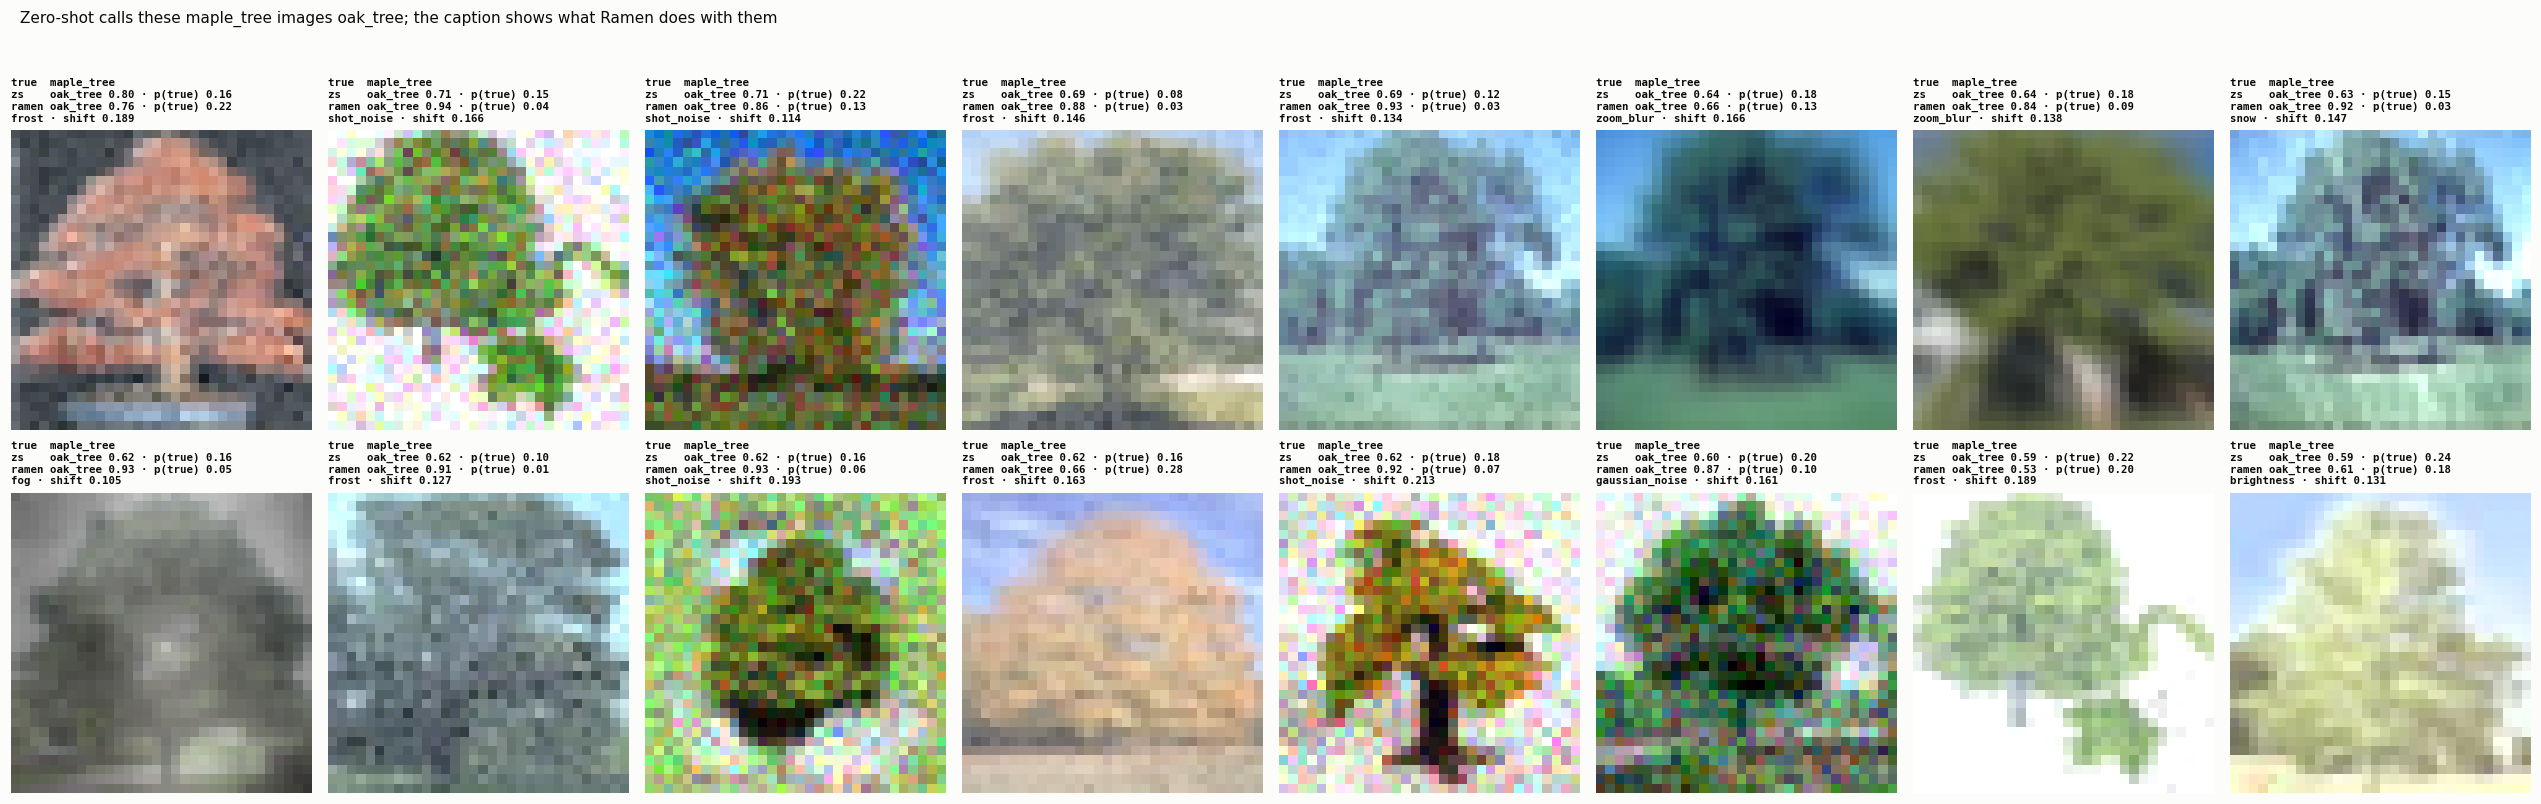

In [13]:
true, pred = FOCUS_PAIR
n_zs, n_ra = zs.pair(true, pred), ra.pair(true, pred)
print(f'{true} -> {pred}: zero-shot {n_zs:,}, Ramen {n_ra:,} (of {int(zs.counts[zs._idx(true)].sum()):,} images of {true})')
exp.gallery.show(true=true, pred=pred, source='zero_shot', n=16, order='confident',
                 title=f'Zero-shot calls these {true} images {pred}; the caption shows what Ramen does with them'); plt.show()

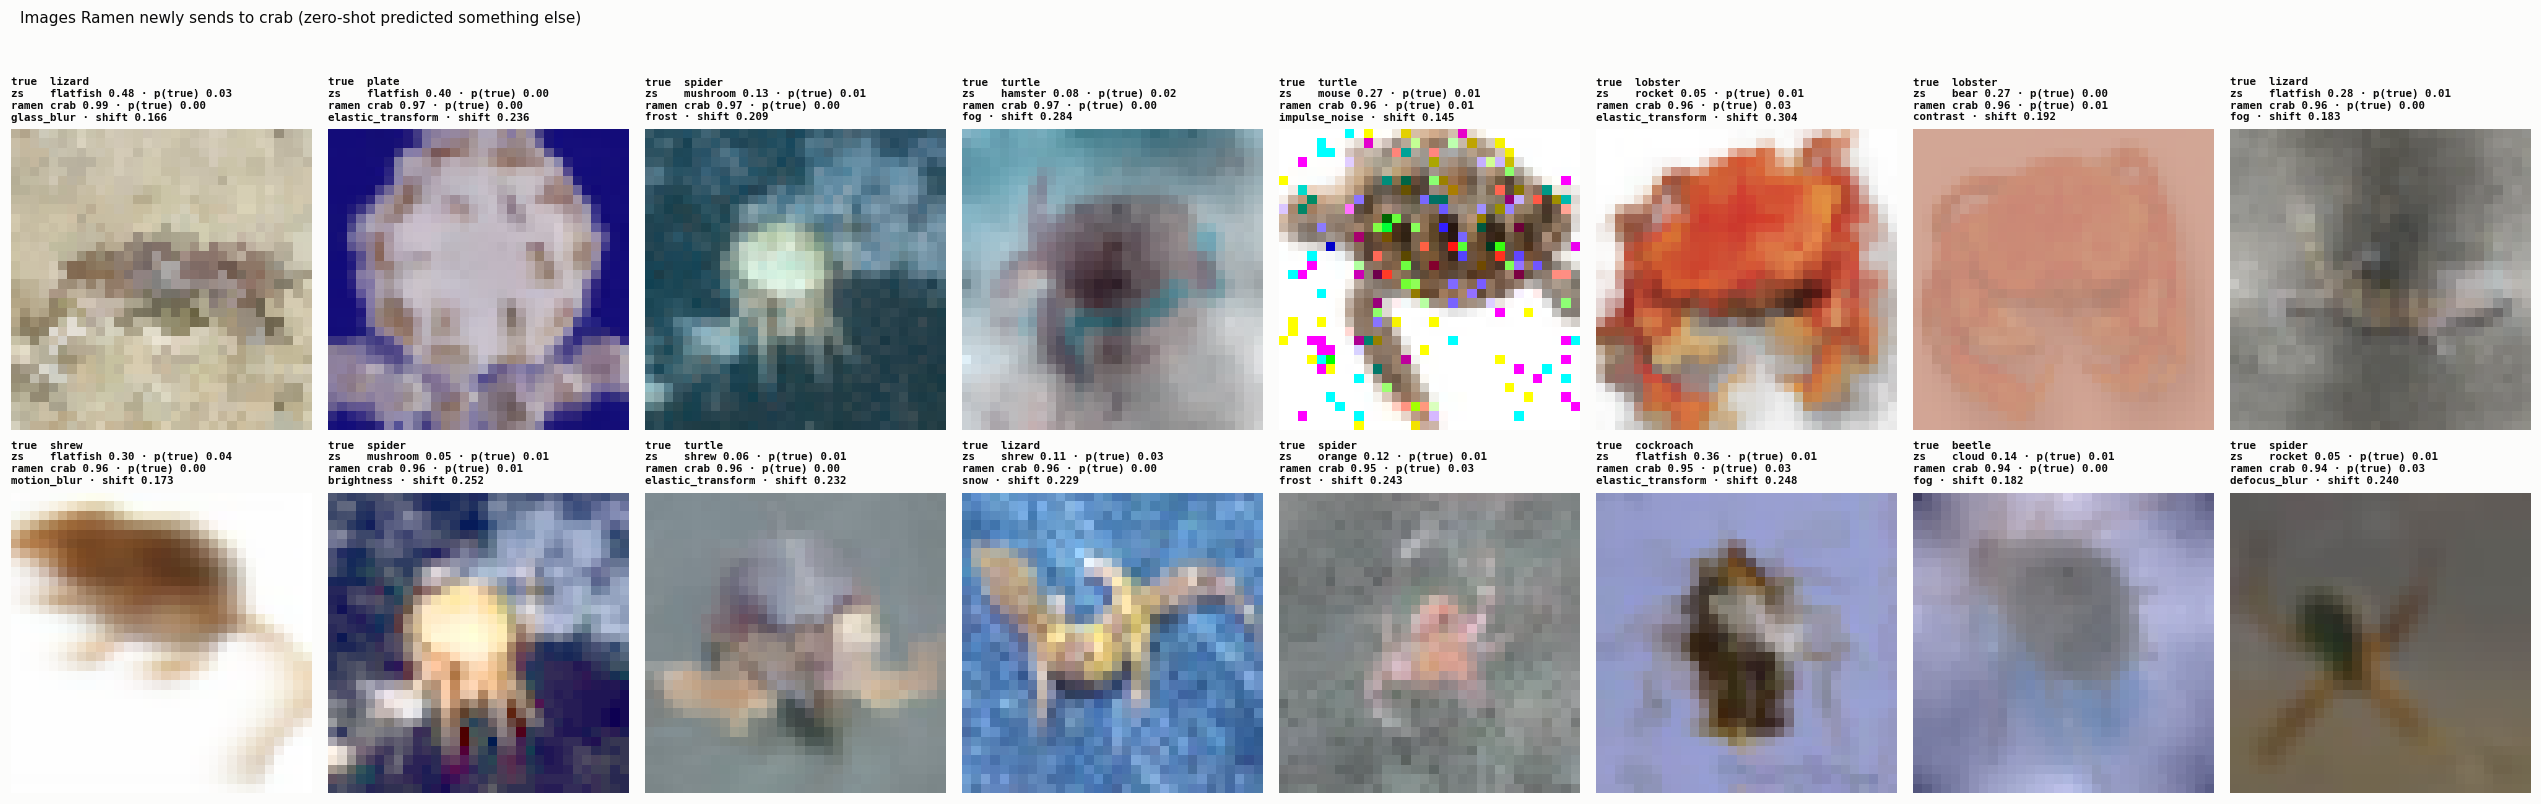

In [14]:
exp.gallery.show(pred=NEW_SINK, correct=False, outcome=['broken', 'wrong -> other wrong'], n=16,
                 title=f'Images Ramen newly sends to {NEW_SINK} (zero-shot predicted something else)'); plt.show()

## 4. Embeddings before and after adaptation

One step on the norm parameters moves each image's embedding a little. The boxes show how far images move, grouped
by outcome. The PCA plot draws an arrow from each image's embedding before adaptation to its embedding after, for
the images of the focus pair's two classes.

,images,median shift,p90 shift,mean shift
outcome,,,,
right -> right,48843,0.15350,0.21226,0.15520
fixed,20301,0.16114,0.22853,0.16281
broken,6792,0.15133,0.21163,0.15410
wrong -> same wrong,30300,0.14689,0.20408,0.14778
wrong -> other wrong,43764,0.15033,0.21405,0.15316


Median shift per domain and outcome (domains move by different amounts, so compare within a row):


outcome,right -> right,fixed,broken,wrong -> same wrong,wrong -> other wrong
domain,,,,,
gaussian_noise,0.1542,0.1471,0.1426,0.1440,0.1352
shot_noise,0.1595,0.1582,0.1470,0.1471,0.1447
impulse_noise,0.0863,0.0910,0.0856,0.0794,0.0821
defocus_blur,0.1471,0.1644,0.1461,0.1453,0.1514
glass_blur,0.1400,0.1525,0.1437,0.1371,0.1483
motion_blur,0.1459,0.1613,0.1441,0.1408,0.1485
zoom_blur,0.1489,0.1650,0.1487,0.1493,0.1564
snow,0.1739,0.1929,0.1753,0.1733,0.1830
frost,0.1629,0.1795,0.1662,0.1660,0.1768


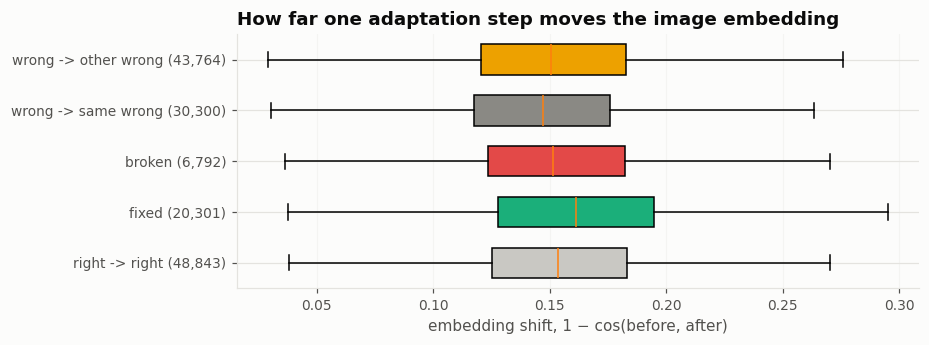

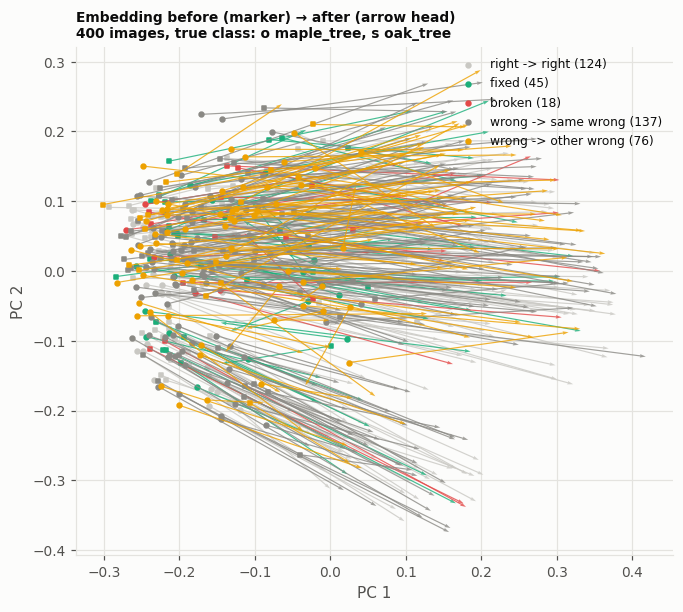

In [15]:
display(exp.embedding_shift_table())
if records.table['domain'].nunique() > 1:
    print('Median shift per domain and outcome (domains move by different amounts, so compare within a row):')
    display(exp.embedding_shift_by_domain())
plots.plot_embedding_shift(records); plt.show()
plots.plot_embedding_moves(records, list(dict.fromkeys(FOCUS_PAIR))); plt.show()

## 5. One image

`gallery.show_image(i)` shows the image with its top classes under zero-shot and under Ramen. The ★ marks the true
class. `records[i]` returns the raw `ImageRecord`, which holds both probability vectors and both embeddings.

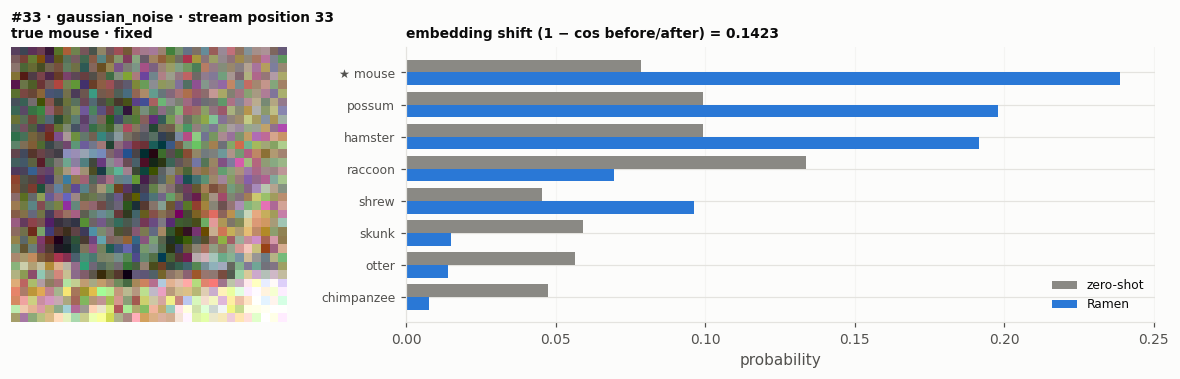

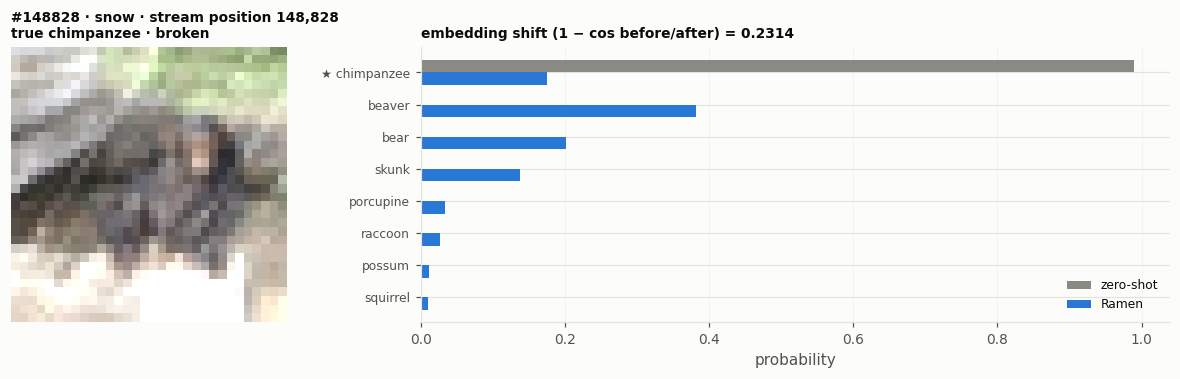

mouse raccoon -> mouse | emb_before (512,) | top-3 Ramen [('mouse', 0.238525390625), ('possum', 0.19775390625), ('hamster', 0.191650390625)]


In [16]:
i = int(records.where(outcome='fixed', domain='gaussian_noise').index[0])
exp.gallery.show_image(i); plt.show()
j = int(records.where(outcome='broken').sort_values('zs_conf', ascending=False).index[0])
exp.gallery.show_image(j); plt.show()
r = records[i]
print(r.true_class, r.zs_class, '->', r.pred_class, '| emb_before', r.emb_before.shape, '| top-3 Ramen', r.top('ramen', 3, records.classes))

## Interpretation (seed 0, full CIFAR-100-C, 150,000 images)

**More errors change wrong class than get fixed.** Zero-shot gets 55,635 of 150,000 right (37.09%) and Ramen gets
69,144 (46.10%). Ramen fixes 20,301 images (13.5%) and breaks 6,792 (4.5%), a net gain of 13,509. Another 43,764
images (29.2%) move from one wrong class to a different one. That is twice the number fixed, and it holds on every
corruption.

**Zero-shot's sinks are mostly relocated, as on DomainNet.** Zero-shot wrongly calls 4,264 images *worm*. Ramen
fixes 1,095 of them (26%), leaves 675 at worm, and moves 2,494 (58%) to other wrong classes (crab 139, snake 129,
trout 128, ...). *mouse* behaves the same way: 4,536 false positives, 825 fixed, 2,866 moved.

**De-sinking can cost a class its own correct predictions.** *keyboard* drops from 2,567 false positives to 256,
but its true positives also fall from 933 to 625 of 1,500. The images it loses go to television, mountain and
road.

**New sinks appear: crab, tractor, lion.** Crab false positives rise from 396 to 1,628, tractor from 543 to 1,524,
and lion from 459 to 1,355. Most of these new errors are unsure: median Ramen confidence is 0.29 for the 1,415
images newly sent to crab and 0.46 for tractor, against 0.87 for Ramen's correct predictions. The most confident
ones are not unsure, though. The crab gallery shows blurred animals with legs radiating from a body (spiders,
turtles, lizards, lobsters) called crab at 0.94–0.99. glass_blur alone gives 429 of the crab errors. tractor is
one of the classes the earlier analyses flagged as a Ramen bias (`watch_classes` in the harness).

**Fine-grained confusions grow.** maple_tree → oak_tree rises from 476 to 509 images and whale → dolphin from 344
to 418. worm → snake rises from 98 to 268 while snake → worm falls from 459 to 220, so Ramen reverses the direction
of that confusion rather than resolving it.

**The size of the embedding step carries no signal here.** Median shift is 0.147–0.161 for every outcome, so fixed
and broken images move the same distance (0.161 vs 0.151). This matches the DomainNet subset, not EuroSAT.

**Caveats.** Seed 0 only. The gain (+9.01) is far above the 0.21 noise floor, but the class and pair counts come
from one stream order.

## Glossary

- **Zero-shot (NoAdapt)**: CLIP classifies by cosine similarity between the image embedding and the text embedding
  of each class name. No adaptation.
- **Ramen**: test-time adaptation. Each image is written into the memory queue of its zero-shot class, together
  with its own entropy gradient. Gradients of the nearest stored images are retrieved, one signSGD step is taken
  on the LayerNorm parameters, the image is predicted, and the parameters are reset.
- **Embedding before / after**: the L2-normalised CLIP image feature with the pretrained / adapted norm parameters.
- **Embedding shift**: 1 − cosine(before, after). 0 means the step did not move the image.
- **TP / FP / FN / TN** (for class *c*): true and predicted *c* / predicted *c* but true other / true *c* but
  predicted other / neither.
- **Precision / recall / F1** (for class *c*): TP / predicted *c*; TP / true *c*; 2TP / (2TP + FP + FN), which is 0
  when TP is 0.
- **Sink**: a class predicted far more often than it occurs (large FP).
- **Sink fate**: what Ramen does with the images zero-shot wrongly sends to a sink. They can be fixed, stay at the
  sink, or move to another wrong class.
- **Sink origin**: for Ramen's false positives of a class, what zero-shot had predicted for them.
- **Outcome**: zero-shot → Ramen correctness of one image. *fixed* = wrong → right; *broken* = right → wrong.
- **Subset (`n_per_domain`)**: a random sample of images per domain, which makes a shorter stream. Ramen's memory
  differs from the full run, so its accuracy is not comparable to the full run.
- **Domain average**: the mean of the per-domain accuracies (the headline convention in this project).